**Phase 3a - Concentration and hourly air-quality evaluation**

Estimate CO, NOx, and NO2 concentrations from hour, weather and the four selected low-cost sensors only:
$$\hat{c}_g = \sum_{j} P(B_g = j \mid \text{hour, T, RH, S1, S3, S4, S5}) \cdot \bar{c}_{g,j}$$

where each bin average $\bar{c}_{g,j}$ is calculated from the training split only.

The primary output is the vector of estimated gas concentrations.

**Evaulation principles**
* **Gases**: CO, Nox, NO2. C6H6 is exclued because it behaves almost like a transform of S2; NMHC is excluded because it is too sparse.
* **Sensors:** S1, S3, S4, S5. S2 is excluded.
* **Weather evidence:** temperature (T) and relative humidity (RH)
* **Network:** each gas has hour as its parent. Sensor parents are specified below, with T and RH included for each sensor.
* **Splits:** blocked train/validation/test splits. Discretizer edges and gas-bin means are learned from training data only
* **Concentration scoring:** MAE and RMSE against observed raw gas concentrations, with a perfect-bin resolution floor for context.
* **AQ sensitivity analysis:** training-set 90th percentile threshold per gas, applied to the estimated concentration vector.

In [ ]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cse250a.modules.config import config
from cse250a.modules.core import TIME_CARDS, Gas, Network, Sensor, Time, Weather
from cse250a.modules.data import Discretizer, blocked_split, load_air_quality
from cse250a.modules.eval.concentration import (
    bin_means,
    concentration_error,
    expected_concentration,
    resolution_floor,
)
from cse250a.modules.eval.metrics import calc_f1
from cse250a.modules.models import DiscreteBN, HourOnlyBaseline

SEEDS = (0, 1, 2)
BIN_COUNTS = (3, 5)
K_VALUES = (2, 3)
RELATIVE_QUANTILE = 0.90
ALPHA = config.bins.alpha

GASES = (Gas.CO, Gas.NOX, Gas.NO2)
SENSORS = (Sensor.S1, Sensor.S3, Sensor.S4, Sensor.S5)
WEATHER = (Weather.T, Weather.RH)
EVIDENCE = (Time.HOUR, *WEATHER, *SENSORS)

PHASE = "phase3a"
RESULTS_DIR = config.paths.results_dir / PHASE
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

print("Gases", GASES)
print("Sensors", SENSORS)
print("Weather", WEATHER)

Gases (<Gas.CO: 'CO(GT)'>, <Gas.NOX: 'NOx(GT)'>, <Gas.NO2: 'NO2(GT)'>)
Sensors (<Sensor.S1: 'PT08.S1(CO)'>, <Sensor.S3: 'PT08.S3(NOx)'>, <Sensor.S4: 'PT08.S4(NO2)'>, <Sensor.S5: 'PT08.S5(O3)'>)
Weather (<Weather.T: 'T'>, <Weather.RH: 'RH'>)


**1. Load the data and define the Phase 2 network**
The Phase 2 edges are:
* S1 $\leftarrow$ CO
* S3 $\leftarrow$ NOx
* S4 $\leftarrow$ NO2, CO, NOx
* S5 $\leftarrow$ CO, NOx

Every sensor also has T and AH as parents. The gas nodes each have hour as their parent. Gas references are prediction targets, never evidence

In [ ]:
raw = load_air_quality(config.paths.air_quality_csv)

# Phase 2 requires observed input variables. Do not drop rows just because a
# reference gas or a sensor is missing: the BN can handle missing observations.
before = len(raw)
raw = raw.dropna(subset=[Time.HOUR, *WEATHER]).copy()
print(f"Rows: {len(raw):,} (removed {before - len(raw):,} with missing hour/weather)")
print("Date range:", raw.index.min(), "to", raw.index.max())

GAS_PARENTS = {
    Sensor.S1: (Gas.CO,),
    Sensor.S3: (Gas.NOX,),
    Sensor.S4: (Gas.NO2, Gas.CO, Gas.NOX),
    Sensor.S5: (Gas.CO, Gas.NOX),
}

def make_network(cards):
    structure = {g: (Time.HOUR,) for g in GASES}
    structure.update({
        sensor: (*GAS_PARENTS[sensor], *WEATHER)
        for sensor in SENSORS
    })
    return Network(structure=structure, cards=cards).validate()

# Quick data-availability check for the four reference gases.
availability = pd.DataFrame({
    "observed": raw[list(GASES)].notna().sum(),
    "missing": raw[list(GASES)].isna().sum(),
    "missing_pct": 100 * raw[list(GASES)].isna().mean(),
})
display(availability)

preview_train, _, _ = blocked_split(raw, seed=SEEDS[0])
preview_disc = Discretizer(n_bins=BIN_COUNTS[0]).fit(
    preview_train, [*GASES, *SENSORS, *WEATHER]
)
preview_cards = {**preview_disc.cards, **TIME_CARDS}
network_preview = make_network(preview_cards)
print(network_preview)

Rows: 8,991 (removed 366 with missing hour/weather)
Date range: 2004-03-10 18:00:00 to 2005-04-04 14:00:00


,observed,missing,missing_pct
CO(GT),7344,1647,18.318318
NOx(GT),7396,1595,17.739962
NO2(GT),7393,1598,17.773329


Network(7 nodes, inputs: hour, T, RH)
          CO(GT) | hour                          CPT shape (24, 3)
         NOx(GT) | hour                          CPT shape (24, 3)
         NO2(GT) | hour                          CPT shape (24, 3)
     PT08.S1(CO) | CO(GT), T, RH                 CPT shape (3, 3, 3, 3)
    PT08.S3(NOx) | NOx(GT), T, RH                CPT shape (3, 3, 3, 3)
    PT08.S4(NO2) | NO2(GT), CO(GT), NOx(GT), T, RH  CPT shape (3, 3, 3, 3, 3, 3)
     PT08.S5(O3) | CO(GT), NOx(GT), T, RH        CPT shape (3, 3, 3, 3, 3)


**2. AQ threshold definition (dataset-relative only)**

For the optional binary AQ sensitivity analysis, each gas threshold is the 90th percentile of that gas in the current training split. The same training-derived thresholds are applied to validation and test data.

A row is labelled bad when at least \(k\) of the three gas concentrations exceed their corresponding thresholds. Rows missing any of the three reference concentrations are excluded from the reference AQ label and its binary metrics.

In [ ]:
def thresholds_for(train_raw):
    return {
        gas: float(train_raw[gas].quantile(RELATIVE_QUANTILE))
        for gas in GASES
    }

def air_quality(concentrations, thresholds, k=2):
    """Return 1 for a bad hour, 0 otherwise; NaN if any gas is unavailable."""
    if not 1 <= k <= len(GASES):
        raise ValueError(f"k must be between 1 and {len(GASES)}")
    if set(thresholds) != set(GASES):
        raise ValueError("Thresholds must contain exactly the three modeled gases.")

    valid = concentrations[list(GASES)].notna().all(axis=1)
    exceedances = pd.DataFrame(
        {gas: concentrations[gas] > thresholds[gas] for gas in GASES},
        index=concentrations.index,
    )
    labels = (exceedances.sum(axis=1) >= k).astype(float)
    return labels.where(valid).rename("AQ_bad")

**3. Helper functions**

binary_metrics() is deliberately defined locally in this notebook. The shared package's score() function scores discrete gas-bin predictions; it is not a binary AQ metric.

The concentration estimator and concentration error functions are imported from the project's shared evaluation helpers.

In [ ]:
def binary_metrics(y_true, y_pred):
    """Binary AQ metrics on rows with both labels observed; F1 via calc_f1."""
    valid = y_true.notna() & y_pred.notna()
    yt = y_true.loc[valid].astype(int).to_numpy()
    yp = y_pred.loc[valid].astype(int).to_numpy()

    tn = int(((yt == 0) & (yp == 0)).sum())
    fp = int(((yt == 0) & (yp == 1)).sum())
    fn = int(((yt == 1) & (yp == 0)).sum())
    tp = int(((yt == 1) & (yp == 1)).sum())

    recall = tp / (tp + fn) if tp + fn else np.nan
    precision = tp / (tp + fp) if tp + fp else np.nan
    # F1 from the shared calc_f1 (bad = class 1). NaN, not 0, when the model never
    # predicts a bad hour or no bad hour exists, so those runs stay distinguishable
    # from "predicted some, got none right" (F1 = 0).
    f1 = calc_f1(yp, yt, 1) if tp + fp and tp + fn else np.nan

    n = len(yt)
    return {
        "n": n,
        "bad_rate": float(yt.mean()) if n else np.nan,
        "predicted_bad_rate": float(yp.mean()) if n else np.nan,
        "recall": recall,
        "precision": precision,
        "F1": f1,
        "accuracy": float((tp + tn) / n) if n else np.nan,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
    }


def make_bin_means(train_raw, train_binned):
    """Training-only representative raw concentration for each gas bin."""
    return {
        gas: bin_means(train_raw[gas], train_binned[gas])
        for gas in GASES
    }


def estimate_all(model, binned, bin_means_by_gas):
    """Return the concentration vector and per-gas posterior bin probabilities."""
    estimates = {}
    probabilities = {}
    for gas in GASES:
        proba = model.predict_proba(binned, gas, EVIDENCE)
        probabilities[gas] = proba
        estimates[gas] = expected_concentration(proba, bin_means_by_gas[gas])
    return pd.DataFrame(estimates, index=binned.index), probabilities

**4. Run the validation grid**
For each bin count and split seed:
1. Make a blocked train/validation/test split
2. Fit the discretizer on **train only** using the three gases, four sensors, and T/RH.
3. Fit the specified Bayesian netowrk and the hour-only baseline.
4. Estimate each gas concentration as posterior bin probabilites multipled by training bin means.
5. Score concentration MAE/RMSE and the perfect-bin resolution floor.

In [ ]:
concentration_rows = []
aq_rows = []
validation_cache = {}
model_cache = {}

for n_bins in BIN_COUNTS:
    for seed in SEEDS:
        train_raw, val_raw, test_raw = blocked_split(raw, seed=seed)

        discretizer = Discretizer(n_bins=n_bins).fit(
            train_raw, [*GASES, *SENSORS, *WEATHER]
        )
        train = discretizer.transform(train_raw)
        val = discretizer.transform(val_raw)
        test = discretizer.transform(test_raw)
        cards = {**discretizer.cards, **TIME_CARDS}

        network = make_network(cards)
        bn = DiscreteBN(network, alpha=ALPHA, seed=seed).fit(train)
        hour = HourOnlyBaseline(cards=cards, alpha=ALPHA).fit(train)

        c_bar = make_bin_means(train_raw, train)
        thresholds = thresholds_for(train_raw)

        bn_est, bn_proba = estimate_all(bn, val, c_bar)
        hour_est, hour_proba = estimate_all(hour, val, c_bar)

        validation_cache[(n_bins, seed)] = {
            "train_raw": train_raw, "val_raw": val_raw, "test_raw": test_raw,
            "train": train, "val": val, "test": test,
            "discretizer": discretizer, "cards": cards, "c_bar": c_bar,
            "thresholds": thresholds, "bn_est": bn_est, "hour_est": hour_est,
            "bn_proba": bn_proba, "hour_proba": hour_proba,
        }
        model_cache[(n_bins, seed)] = {"bn": bn, "hour": hour}

        bn_est.to_csv(
            RESULTS_DIR / f"estimates_bn_bins{n_bins}_seed{seed}_val.csv",
            index_label="datetime",
        )
        hour_est.to_csv(
            RESULTS_DIR / f"estimates_hour_bins{n_bins}_seed{seed}_val.csv",
            index_label="datetime",
        )

        for gas in GASES:
            for model_name, estimates in (
                ("BN", bn_est), ("HourOnlyBaseline", hour_est)
            ):
                concentration_rows.append({
                    "bins": n_bins, "seed": seed, "gas": str(gas),
                    "model": model_name,
                    **concentration_error(estimates[gas], val_raw[gas]),
                })
            concentration_rows.append({
                "bins": n_bins, "seed": seed, "gas": str(gas),
                "model": "resolution_floor",
                **resolution_floor(val_raw[gas], val[gas], c_bar[gas]),
            })

        for k in K_VALUES:
            aq_reference = air_quality(val_raw, thresholds, k=k)
            for model_name, estimates in (
                ("BN", bn_est), ("HourOnlyBaseline", hour_est)
            ):
                aq_prediction = air_quality(estimates, thresholds, k=k)
                aq_rows.append({
                    "bins": n_bins, "seed": seed, "k": k,
                    "model": model_name,
                    **binary_metrics(aq_reference, aq_prediction),
                })

        n_iter = bn.result.n_iter if bn.result is not None else "n/a"
        print(f"Finished bins={n_bins}, seed={seed}; BN EM iterations={n_iter}")

concentration_grid = pd.DataFrame(concentration_rows)
aq_grid = pd.DataFrame(aq_rows)
concentration_grid.to_csv(RESULTS_DIR / "concentration_grid.csv", index=False)
aq_grid.to_csv(RESULTS_DIR / "aq_grid_relative.csv", index=False)
print("Saved validation concentration and relative-AQ tables.")

Finished bins=3, seed=0; BN EM iterations=5


Finished bins=3, seed=1; BN EM iterations=4


Finished bins=3, seed=2; BN EM iterations=4


Finished bins=5, seed=0; BN EM iterations=6


Finished bins=5, seed=1; BN EM iterations=5


Finished bins=5, seed=2; BN EM iterations=5
Saved validation concentration and relative-AQ tables.


**5. Per-gas concentration results**

Report the mean and standard deviation across the three blocked-split seeds. Every model is scored on observed validatioon reference readings. Compare the BN with the hour-only baseline and the resolution for each gas.

In [ ]:
concentration_summary = (
    concentration_grid
    .groupby(["bins", "gas", "model"])
    .agg(
        n_mean=("n", "mean"),
        MAE_mean=("MAE", "mean"), MAE_std=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"), RMSE_std=("RMSE", "std"),
    )
    .reset_index()
)
display(concentration_summary.round(4))

concentration_report = concentration_summary.copy()
concentration_report["MAE (mean ± std)"] = concentration_report.apply(
    lambda row: f"{row['MAE_mean']:.3f} ± {row['MAE_std']:.3f}", axis=1
)
concentration_report["RMSE (mean ± std)"] = concentration_report.apply(
    lambda row: f"{row['RMSE_mean']:.3f} ± {row['RMSE_std']:.3f}", axis=1
)
display(concentration_report[
    ["bins", "gas", "model", "n_mean", "MAE (mean ± std)", "RMSE (mean ± std)"]
])

,bins,gas,model,n_mean,MAE_mean,MAE_std,RMSE_mean,RMSE_std
0,3,CO(GT),BN,1853.0000,0.5437,0.0448,0.8047,0.0679
1,3,CO(GT),HourOnlyBaseline,1853.0000,0.8570,0.0391,1.1511,0.0356
2,3,CO(GT),resolution_floor,1853.0000,0.4608,0.0579,0.7058,0.0937
3,3,NO2(GT),BN,1854.6667,31.0796,2.4407,40.5628,3.5565
4,3,NO2(GT),HourOnlyBaseline,1854.6667,31.9767,2.8023,41.4433,3.9894
5,3,NO2(GT),resolution_floor,1854.6667,16.9806,1.7566,23.1349,3.5182
6,3,NOx(GT),BN,1855.0000,91.7509,0.0736,134.1168,11.7085
7,3,NOx(GT),HourOnlyBaseline,1855.0000,136.4695,5.5857,186.4560,19.5856
8,3,NOx(GT),resolution_floor,1855.0000,74.1312,18.1980,116.9653,26.7962
9,5,CO(GT),BN,1853.0000,0.4875,0.0444,0.7168,0.0634


,bins,gas,model,n_mean,MAE (mean ± std),RMSE (mean ± std)
0,3,CO(GT),BN,1853.000000,0.544 ± 0.045,0.805 ± 0.068
1,3,CO(GT),HourOnlyBaseline,1853.000000,0.857 ± 0.039,1.151 ± 0.036
2,3,CO(GT),resolution_floor,1853.000000,0.461 ± 0.058,0.706 ± 0.094
3,3,NO2(GT),BN,1854.666667,31.080 ± 2.441,40.563 ± 3.556
4,3,NO2(GT),HourOnlyBaseline,1854.666667,31.977 ± 2.802,41.443 ± 3.989
5,3,NO2(GT),resolution_floor,1854.666667,16.981 ± 1.757,23.135 ± 3.518
6,3,NOx(GT),BN,1855.000000,91.751 ± 0.074,134.117 ± 11.709
7,3,NOx(GT),HourOnlyBaseline,1855.000000,136.469 ± 5.586,186.456 ± 19.586
8,3,NOx(GT),resolution_floor,1855.000000,74.131 ± 18.198,116.965 ± 26.796
9,5,CO(GT),BN,1853.000000,0.488 ± 0.044,0.717 ± 0.063


**6. Optional dataset-relative AQ results**

These metrics are secondary to the concentration-vector evaluation.

In [ ]:
aq_summary = (
    aq_grid
    .groupby(["k", "bins", "model"])
    .agg(
        n_mean=("n", "mean"),
        bad_rate_mean=("bad_rate", "mean"),
        predicted_bad_rate_mean=("predicted_bad_rate", "mean"),
        recall_mean=("recall", "mean"), recall_std=("recall", "std"),
        precision_mean=("precision", "mean"), precision_std=("precision", "std"),
        F1_mean=("F1", "mean"), F1_std=("F1", "std"),
        accuracy_mean=("accuracy", "mean"), accuracy_std=("accuracy", "std"),
    )
    .reset_index()
)
display(aq_summary.round(4))

aq_report = aq_summary.copy()
for metric in ("recall", "precision", "F1", "accuracy"):
    aq_report[f"{metric} (mean ± std)"] = aq_report.apply(
        lambda row, m=metric: (
            f"{row[f'{m}_mean']:.3f} ± {row[f'{m}_std']:.3f}"
            if pd.notna(row[f"{m}_mean"]) and pd.notna(row[f"{m}_std"])
            else "n/a"
        ), axis=1
    )
display(aq_report[[
    "k", "bins", "model", "n_mean", "bad_rate_mean",
    "recall (mean ± std)", "precision (mean ± std)",
    "F1 (mean ± std)", "accuracy (mean ± std)",
]])

,k,bins,model,n_mean,bad_rate_mean,predicted_bad_rate_mean,recall_mean,recall_std,precision_mean,precision_std,F1_mean,F1_std,accuracy_mean,accuracy_std
0,2,3,BN,1749.6667,0.1013,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,0.8987,0.0320
1,2,3,HourOnlyBaseline,1749.6667,0.1013,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,0.8987,0.0320
2,2,5,BN,1749.6667,0.1013,0.0705,0.4025,0.1529,0.5907,0.0983,0.4677,0.108,0.9128,0.0192
3,2,5,HourOnlyBaseline,1749.6667,0.1013,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,0.8987,0.0320
4,3,3,BN,1749.6667,0.0377,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,0.9623,0.0154
5,3,3,HourOnlyBaseline,1749.6667,0.0377,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,0.9623,0.0154
6,3,5,BN,1749.6667,0.0377,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,0.9623,0.0154
7,3,5,HourOnlyBaseline,1749.6667,0.0377,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,0.9623,0.0154


,k,bins,model,n_mean,bad_rate_mean,recall (mean ± std),precision (mean ± std),F1 (mean ± std),accuracy (mean ± std)
0,2,3,BN,1749.666667,0.101284,0.000 ± 0.000,n/a,n/a,0.899 ± 0.032
1,2,3,HourOnlyBaseline,1749.666667,0.101284,0.000 ± 0.000,n/a,n/a,0.899 ± 0.032
2,2,5,BN,1749.666667,0.101284,0.403 ± 0.153,0.591 ± 0.098,0.468 ± 0.108,0.913 ± 0.019
3,2,5,HourOnlyBaseline,1749.666667,0.101284,0.000 ± 0.000,n/a,n/a,0.899 ± 0.032
4,3,3,BN,1749.666667,0.037729,0.000 ± 0.000,n/a,n/a,0.962 ± 0.015
5,3,3,HourOnlyBaseline,1749.666667,0.037729,0.000 ± 0.000,n/a,n/a,0.962 ± 0.015
6,3,5,BN,1749.666667,0.037729,0.000 ± 0.000,n/a,n/a,0.962 ± 0.015
7,3,5,HourOnlyBaseline,1749.666667,0.037729,0.000 ± 0.000,n/a,n/a,0.962 ± 0.015


**7. Select the configuration using validation only**

The primary model-selection criterion is the mean validation F1 of the BN in the optional relative-AQ analysis. The concentration tables remain the main scientific result and should also be considered when interpreting the selected configuration. The representative seed is the seed whose F1 is closest to the three-seed mean.

In [ ]:
bn_only = aq_summary[aq_summary["model"] == "BN"].copy()
eligible = bn_only[bn_only["F1_mean"].notna()].copy()
if eligible.empty:
    raise RuntimeError(
        "No validation configuration has defined F1. Inspect relative-AQ "
        "prevalence and missing reference concentrations."
    )

best_row = eligible.sort_values(
    ["F1_mean", "recall_mean", "precision_mean"],
    ascending=False,
).iloc[0]

CHOSEN_K = int(best_row["k"])
CHOSEN_BINS = int(best_row["bins"])

seed_rows = aq_grid[
    (aq_grid["model"] == "BN")
    & (aq_grid["k"] == CHOSEN_K)
    & (aq_grid["bins"] == CHOSEN_BINS)
]
target_f1 = seed_rows["F1"].mean()
CHOSEN_SEED = int(
    seed_rows.assign(distance=(seed_rows["F1"] - target_f1).abs())
    .sort_values("distance")
    .iloc[0]["seed"]
)

chosen = validation_cache[(CHOSEN_BINS, CHOSEN_SEED)]
chosen_thresholds = chosen["thresholds"]

print({
    "threshold": f"training-set {RELATIVE_QUANTILE:.0%} quantile",
    "k": CHOSEN_K,
    "bins": CHOSEN_BINS,
    "representative_seed": CHOSEN_SEED,
    "validation_BN_F1_mean": float(best_row["F1_mean"]),
    "validation_BN_recall_mean": float(best_row["recall_mean"]),
    "validation_BN_precision_mean": float(best_row["precision_mean"]),
})
print("Training-derived thresholds:", {
    str(gas): value for gas, value in chosen_thresholds.items()
})

{'threshold': 'training-set 90% quantile', 'k': 2, 'bins': 5, 'representative_seed': 1, 'validation_BN_F1_mean': 0.4676796160305982, 'validation_BN_recall_mean': 0.40250714621424005, 'validation_BN_precision_mean': 0.5907203907203907}
Training-derived thresholds: {'CO(GT)': 4.0, 'NOx(GT)': 485.0, 'NO2(GT)': 169.0}


**8. Figures** 

The figures below are generated from validation results and saved to figures/phase3a/.

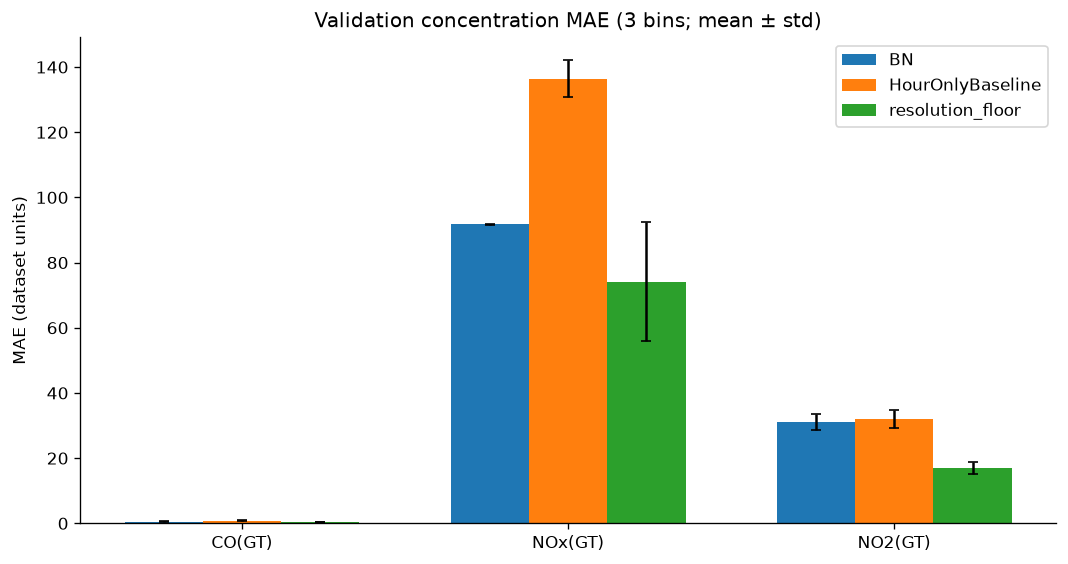

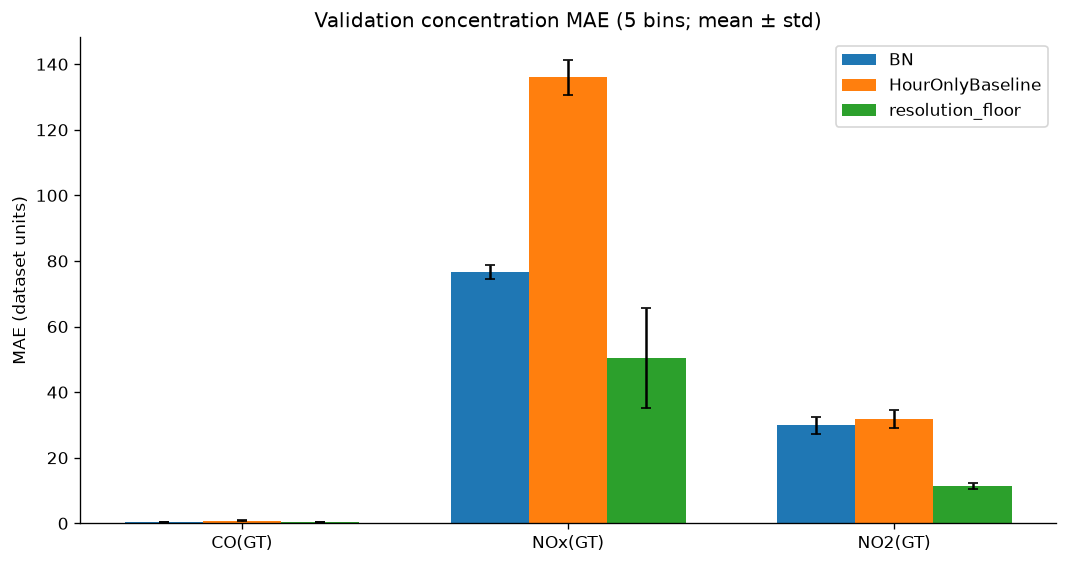

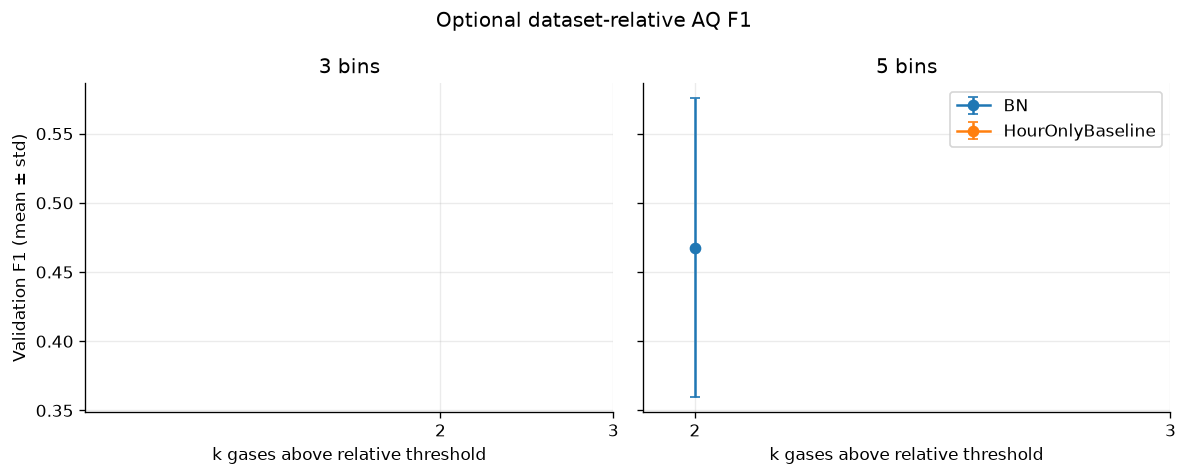

In [ ]:
# Figure 1: concentration MAE by gas and model, one plot per bin count.
for n_bins in BIN_COUNTS:
    plot_data = concentration_summary[concentration_summary["bins"] == n_bins]
    gas_labels = [str(gas) for gas in GASES]
    model_names = ["BN", "HourOnlyBaseline", "resolution_floor"]
    x = np.arange(len(gas_labels))
    width = 0.24

    fig, ax = plt.subplots(figsize=(9, 4.8))
    for j, model_name in enumerate(model_names):
        sub = (
            plot_data[plot_data["model"] == model_name]
            .set_index("gas")
            .reindex(gas_labels)
        )
        ax.bar(
            x + (j - 1) * width,
            sub["MAE_mean"],
            width,
            yerr=sub["MAE_std"],
            capsize=3,
            label=model_name,
        )
    ax.set_xticks(x, gas_labels)
    ax.set_ylabel("MAE (dataset units)")
    ax.set_title(f"Validation concentration MAE ({n_bins} bins; mean ± std)")
    ax.legend()
    fig.tight_layout()
    fig.savefig(config.paths.figure(PHASE, f"concentration_mae_{n_bins}bins.png"), bbox_inches="tight")
    plt.show()

# Figure 2: optional relative-AQ F1 across k.
fig, axes = plt.subplots(1, len(BIN_COUNTS), figsize=(10, 4), sharey=True)
if len(BIN_COUNTS) == 1:
    axes = [axes]
for ax, n_bins in zip(axes, BIN_COUNTS):
    sub = aq_summary[aq_summary["bins"] == n_bins]
    for model_name in ("BN", "HourOnlyBaseline"):
        model_data = sub[sub["model"] == model_name].set_index("k").reindex(K_VALUES)
        ax.errorbar(
            K_VALUES, model_data["F1_mean"], yerr=model_data["F1_std"],
            marker="o", capsize=3, label=model_name,
        )
    ax.set_xticks(K_VALUES)
    ax.set_xlabel("k gases above relative threshold")
    ax.set_title(f"{n_bins} bins")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Validation F1 (mean ± std)")
axes[-1].legend()
fig.suptitle("Optional dataset-relative AQ F1")
fig.tight_layout()
fig.savefig(config.paths.figure(PHASE, "aq_f1_relative.png"), bbox_inches="tight")
plt.show()

**9. Inspect false-negative bad hours and the top-bin cap**

The expected-concentration estimatior is bounded above by the largest training bin mean. Consequently, reference spikes above that value cannot be reconstructed exactly. The table below checks whether false-negative AQ hours contain one or more reference readings above the corresponding gas' top-bin mean.

In [ ]:
val_raw = chosen["val_raw"]
bn_est = chosen["bn_est"]
aq_true = air_quality(val_raw, chosen_thresholds, k=CHOSEN_K)
aq_bn = air_quality(bn_est, chosen_thresholds, k=CHOSEN_K)
false_negative_mask = (aq_true == 1) & (aq_bn == 0)

false_negative_rows = []
for timestamp in val_raw.index[false_negative_mask.fillna(False)]:
    above_cap = [
        str(gas)
        for gas in GASES
        if pd.notna(val_raw.at[timestamp, gas])
        and val_raw.at[timestamp, gas] > float(chosen["c_bar"][gas].max())
    ]
    false_negative_rows.append({
        "timestamp": timestamp,
        "gases_above_top_bin_mean": ", ".join(above_cap) if above_cap else "none",
    })

false_negative_spikes = pd.DataFrame(false_negative_rows)
n_false_negatives = int(false_negative_mask.sum())
n_above_cap = (
    int(false_negative_spikes["gases_above_top_bin_mean"].ne("none").sum())
    if not false_negative_spikes.empty else 0
)
print("False-negative relative-AQ hours:", n_false_negatives)
print("False negatives with at least one reference above its top-bin mean:", n_above_cap)
display(false_negative_spikes.head(30))

False-negative relative-AQ hours: 134
False negatives with at least one reference above its top-bin mean: 132


,timestamp,gases_above_top_bin_mean
0,2004-03-17 19:00:00,"CO(GT), NO2(GT)"
1,2004-03-17 20:00:00,"CO(GT), NO2(GT)"
2,2004-03-17 21:00:00,"CO(GT), NO2(GT)"
3,2004-03-18 20:00:00,CO(GT)
4,2004-04-08 19:00:00,CO(GT)
5,2004-09-08 19:00:00,CO(GT)
6,2004-09-09 10:00:00,NOx(GT)
7,2004-09-09 17:00:00,NO2(GT)
8,2004-09-09 18:00:00,"CO(GT), NOx(GT), NO2(GT)"
9,2004-09-09 19:00:00,CO(GT)


In [ ]:
# Save the selected validation concentration vector and optional AQ diagnostics.
chosen_val_estimates = chosen["bn_est"].copy()
chosen_val_estimates["AQ_reference_relative"] = aq_true
chosen_val_estimates["AQ_BN_relative"] = aq_bn
chosen_val_estimates.to_csv(
    RESULTS_DIR / f"estimates_val_bins{CHOSEN_BINS}_seed{CHOSEN_SEED}.csv",
    index_label="datetime",
)
false_negative_spikes.to_csv(
    RESULTS_DIR / "false_negative_spikes_val.csv", index=False
)

**10. Final test evaluation - selected configuration only**

The selected discretizer and fitted models are reused from the chosen (bins, seed) run. No test labels or test metrics were used for selection. Each model predicts each gas once on the test split, and the AQ metrics are then computed for the chosen threshold family and k.

In [ ]:
test_raw = chosen["test_raw"]
test_binned = chosen["test"]
test_c_bar = chosen["c_bar"]

bn = model_cache[(CHOSEN_BINS, CHOSEN_SEED)]["bn"]
hour = model_cache[(CHOSEN_BINS, CHOSEN_SEED)]["hour"]

test_bn_est, test_bn_proba = estimate_all(bn, test_binned, test_c_bar)
test_hour_est, test_hour_proba = estimate_all(hour, test_binned, test_c_bar)

test_concentration_rows = []
for gas in GASES:
    for model_name, estimates in (
        ("BN", test_bn_est), ("HourOnlyBaseline", test_hour_est)
    ):
        test_concentration_rows.append({
            "gas": str(gas), "model": model_name,
            **concentration_error(estimates[gas], test_raw[gas]),
        })
    test_concentration_rows.append({
        "gas": str(gas), "model": "resolution_floor",
        **resolution_floor(test_raw[gas], test_binned[gas], test_c_bar[gas]),
    })

test_concentration = pd.DataFrame(test_concentration_rows)
display(test_concentration)

test_aq_true = air_quality(test_raw, chosen_thresholds, k=CHOSEN_K)
test_aq_bn = air_quality(test_bn_est, chosen_thresholds, k=CHOSEN_K)
test_aq_hour = air_quality(test_hour_est, chosen_thresholds, k=CHOSEN_K)

test_aq = pd.DataFrame([
    {"model": "BN", **binary_metrics(test_aq_true, test_aq_bn)},
    {"model": "HourOnlyBaseline", **binary_metrics(test_aq_true, test_aq_hour)},
])
display(test_aq)

test_output = test_bn_est.copy()
test_output["AQ_reference_relative"] = test_aq_true
test_output["AQ_BN_relative"] = test_aq_bn
test_output["AQ_HourOnlyBaseline_relative"] = test_aq_hour

test_output.to_csv(RESULTS_DIR / "estimates_test_selected.csv", index_label="datetime")
test_hour_est.to_csv(RESULTS_DIR / "estimates_hour_test_selected.csv", index_label="datetime")
test_concentration.to_csv(RESULTS_DIR / "concentration_test_selected.csv", index=False)
test_aq.to_csv(RESULTS_DIR / "aq_test_relative_selected.csv", index=False)

,gas,model,n,MAE,RMSE
0,CO(GT),BN,1848,0.532740,0.872641
1,CO(GT),HourOnlyBaseline,1848,0.948169,1.362588
2,CO(GT),resolution_floor,1848,0.383063,0.743599
3,NOx(GT),BN,1865,82.400565,137.968838
4,NOx(GT),HourOnlyBaseline,1865,149.352896,216.781476
5,NOx(GT),resolution_floor,1865,56.573879,116.957110
6,NO2(GT),BN,1864,28.419484,37.926889
7,NO2(GT),HourOnlyBaseline,1864,30.712237,40.188960
8,NO2(GT),resolution_floor,1864,11.124034,16.638410


,model,n,bad_rate,predicted_bad_rate,recall,precision,F1,accuracy,TN,FP,FN,TP
0,BN,1759,0.132462,0.0722,0.390558,0.716535,0.505556,0.898806,1490,36,142,91
1,HourOnlyBaseline,1759,0.132462,0.0000,0.000000,NaN,NaN,0.867538,1526,0,233,0


**12. Interpretation and limitations**

**Interpretations**

The BN significantly outperforms the Hour-Only Baseline across evaluated gas concentrations (CO, NOx, and NO2), with performance improving future as the number of bins increases from 3 to 5.

$\text{CO(GT)}$: The $\text{BN}$ achieves significantly lower errors. For example, at 5 bins, the $\text{BN}$ records an MAE of $0.488 \pm 0.044$ and RMSE of $0.717 \pm 0.063$, compared to the baseline's MAE of $0.845 \pm 0.039$ and RMSE of $1.142 \pm 0.033$.   

$\text{NO2(GT)}$: The $\text{BN}$ shows modest improvements over the baseline, yielding an MAE of $29.880 \pm 2.553$ (vs. $31.838$ for the baseline) at 5 bins.   

$\text{NOx(GT)}$: The $\text{BN}$ delivers substantial gains, lowering the MAE to $76.685 \pm 2.118$ (at 5 bins) compared to the baseline's $135.970 \pm 5.211$.

When analyzing the MAE relative to the resolution floor, a small gap indicates that the chosen binning granularity is acting as a primary bottleneck preventing further error reduction. Because continuous distributions are mapped to discrete bins, quantization error inherently caps the precision of the predictions.

The relative-air-quality results should strictly be treated as a secondary sensitivity analysis rather than official regulatory Air Quality Index (AQI) or compliance metrics. They evaluate internal model robustness rather than real-world statutory thresholds.

Because the final estimate is calculated as a posterior expectation over discretized bins (bin probabilities multiplied by bin averages), it is mathematically bounded by the largest training-bin mean. Consequently, the model will inherently underestimate extreme upper-tail observations or pollution spikes that exceed the highest bin boundary.

The model operates as a static, same-hour network. It evaluates contemporaneous relationships within the same timestamp and does not incorporate temporal transition probabilities or transition edges between adjacent hours.

$\text{C}_6\text{H}_6$ and sensor $\text{S2}$ are entirely excluded from the network topology. Because $\text{C}_6\text{H}_6$ functions primarily as a transformation of $\text{S2}$ rather than independent evidence, results from this model must not be described as validating $\text{C}_6\text{H}_6$ recovery. $\text{NMHC}$ is left out of the experiment because its data missingness is too high, preventing any meaningful or reliable accuracy evaluation.

**Limitations to Report**
* This rule on point estimates returns one yes/no label per hour; it does not estimate P(AQ = bad)
* It ignores the joint dependence among gases when several concentrations are uncertain simultaneously. Four marginal expected concentrations do not preserved cross-gas posterior co-movement
* The estimate cannot exceed a gas' largest training-bin mean, so extreme spikes are systematically underestimated and some true bad hours can be missed.
* The official limits do not all describe one-hour averages. In particular, applying annual or 8-hour limits to hourly readinsg is not a regulartory AQI calculation.
* The Phase 2 network is a static same-four model; it does not use temporal transitions between adjacent hours.
